<a href="https://colab.research.google.com/github/saratyulyuova/tenge-ruble-network/blob/main/network_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tenge and Ruble in the Emerging-Market Currency Network, 2015–2026

**Author:** Sara Tyulyuova

**Research question:** How did the network position of the Kazakhstani tenge relative to the Russian ruble change after February 2022?

**H₀:** The correlation-based network distance between KZT and RUB is the same before and after 24 February 2022.
**H₁:** The distance changed (two-sided test).

## 1. Setup and data

In [4]:
!pip install -q yfinance networkx


In [5]:
import yfinance as yf          # downloads market data from Yahoo Finance
import pandas as pd            # tables (DataFrames) and time series
import numpy as np             # fast math on arrays
import matplotlib.pyplot as plt  # plots
import networkx as nx          # graphs and minimum spanning trees

print("pandas", pd.__version__, "| numpy", np.__version__, "| yfinance", yf.__version__)

pandas 2.2.3 | numpy 2.1.3 | yfinance 0.2.66


In [6]:
tickers = ["KZT=X", "RUB=X"]   # KZT=X means: how many tenge for 1 US dollar

raw = yf.download(tickers, start="2015-08-01", end="2026-10-01", progress=False)
px = raw["Close"]              # keep only daily closing prices
px.columns = ["KZT", "RUB"]    # short readable names

px.head()


/tmp/ipykernel_2423/59499654.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw = yf.download(tickers, start="2015-08-01", end="2026-10-01", progress=False)


,KZT,RUB
Date,,
2015-08-03,185.410004,61.630699
2015-08-04,184.770004,63.500000
2015-08-05,184.899994,63.110001
2015-08-06,184.240005,63.382999
2015-08-07,184.929993,64.480003


In [7]:
print("Shape:", px.shape)                       # (rows, columns)
print("From", px.index.min().date(), "to", px.index.max().date())
print("\nMissing values:\n", px.isna().sum())
print("\nSummary:\n", px.describe().round(2))
print("\nLast 5 rows:\n", px.tail())

Shape: (2905, 2)
From 2015-08-03 to 2026-09-30

Missing values:
 KZT    0
RUB    0
dtype: int64

Summary:
            KZT      RUB
count  2905.00  2905.00
mean    410.76    73.09
std      67.69    12.26
min     184.24     0.72
25%     344.85    63.76
50%     423.62    72.48
75%     460.86    79.85
max     546.96   138.97

Last 5 rows:
                    KZT        RUB
Date                             
2026-09-24  429.468536  84.772919
2026-09-25  426.548492  84.998657
2026-09-28  427.972076  81.902596
2026-09-29  424.581116  84.494904
2026-09-30  423.849579  83.745300


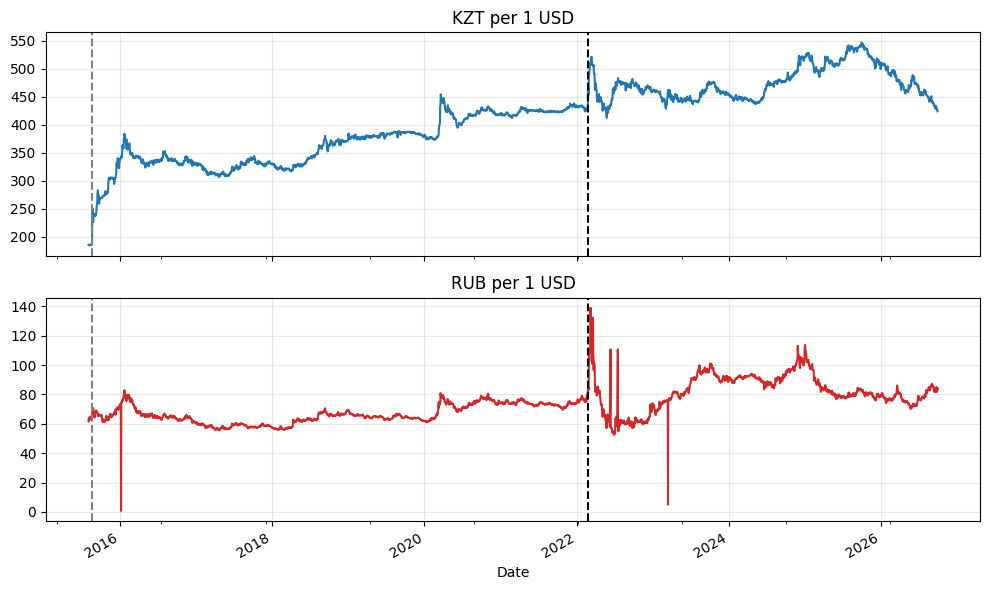

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

px["KZT"].plot(ax=axes[0], color="tab:blue", title="KZT per 1 USD")
px["RUB"].plot(ax=axes[1], color="tab:red", title="RUB per 1 USD")

for ax in axes:
    ax.axvline(pd.Timestamp("2015-08-20"), ls="--", color="gray")   # tenge free float
    ax.axvline(pd.Timestamp("2022-02-24"), ls="--", color="black")  # start of "post" period
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
from google.colab import drive
drive.mount("/content/drive")

import os
folder = "/content/drive/MyDrive/tenge-ruble-network/data"
os.makedirs(folder, exist_ok=True)
px.to_csv(f"{folder}/kzt_rub_test.csv")
print("Saved to", folder)


Mounted at /content/drive
Saved to /content/drive/MyDrive/tenge-ruble-network/data
